# ADP 15회 상황형 연습 - 풀이

**상황형 재구성 연습·예시 풀이이며 공식 원문/정답이 아닙니다.**

출처: DataManim ADP 15회 실기 문제 PDF

원 자료 조건: 첨부 자료의 문항·표·그림을 바탕으로 정리한 학습용 자료입니다.

문제는 동봉 상황형 문제지와 같습니다. 원문은 문항목록.json·추가_문항명세.json에 보존합니다. 순서대로 실행하며 각 대문항에서 고정한 자료·전처리·분할을 후속 문항에 재사용합니다. 통계 답안은 선정 근거 → 가정·가설 → 통계량·p-value → 기각 여부·상황 해석 순서로 작성합니다. 확률·구간 추정·관리도 문항에 불필요한 귀무가설을 만들지 않습니다.

실행: 해당 회차 폴더에서 위에서 아래로 실행합니다. 가설검정_답안.json은 실제 계산한 가설·수치·결론 기록입니다.

In [1]:
from pathlib import Path
import sys, platform, time, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
    roc_auc_score, average_precision_score, mean_squared_error, mean_absolute_error, r2_score,
    silhouette_score)
from sklearn.inspection import permutation_importance
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

SEED = 42
HERE = Path.cwd()
DATA = HERE / 'data'
assert DATA.is_dir(), '압축을 전체 해제한 뒤, 노트북이 있는 회차 폴더를 작업 위치로 실행하세요.'
OUT = HERE / '실행결과'
OUT.mkdir(exist_ok=True)
font_path = HERE.parent / '공통' / 'NanumGothic-Regular.ttf'
if font_path.is_file():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 20)
print('Python', platform.python_version())
import sklearn, scipy, statsmodels, imblearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scikit-learn', sklearn.__version__,
      'scipy', scipy.__version__, 'statsmodels', statsmodels.__version__, 'imblearn', imblearn.__version__)

def load(name):
    return pd.read_csv(DATA / name if (DATA / name).exists() else DATA / (name + ".gz"))

def ohe():
    return OneHotEncoder(handle_unknown='ignore', **({'sparse_output': False} if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else {'sparse': False}))

def reg_metrics(actual, predicted):
    a, b = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    assert a.shape == b.shape and np.isfinite(a).all() and np.isfinite(b).all()
    mask = a != 0
    return {'MSE': mean_squared_error(a,b), 'RMSE': np.sqrt(mean_squared_error(a,b)),
            'MAE': mean_absolute_error(a,b), 'MAPE(%)': 100*np.mean(np.abs((a[mask]-b[mask])/a[mask])) if mask.any() else np.nan,
            'MAPE 제외 0개수': int((~mask).sum()), 'R2': r2_score(a,b)}

def class_metrics(actual, predicted, probability=None):
    a, b = np.asarray(actual), np.asarray(predicted)
    assert a.shape == b.shape
    result = {'Accuracy':accuracy_score(a,b), 'BalancedAccuracy':balanced_accuracy_score(a,b),
              'F1_macro':f1_score(a,b,average='macro',zero_division=0),
              'F1_weighted':f1_score(a,b,average='weighted',zero_division=0)}
    if probability is not None and set(np.unique(a)) == {0,1}:
        score = np.asarray(probability)
        score = score[:,1] if score.ndim == 2 else score
        result.update(ROC_AUC=roc_auc_score(a,score), AveragePrecision=average_precision_score(a,score))
    return result

def decision(p, alpha=.05):
    return '귀무가설 기각' if p < alpha else '귀무가설을 기각할 근거 부족'

def quality(frame):
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str), 'missing':frame.isna().sum(), 'unique':frame.nunique()}))
    print('shape:', frame.shape, 'duplicate rows:', frame.duplicated().sum())
    display(frame.describe(include='all').T)

def plot_confusion(actual, prediction, labels=None, title='Confusion matrix'):
    order = np.unique(np.r_[actual,prediction]) if labels is None else labels
    matrix=confusion_matrix(actual,prediction,labels=order)
    fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(matrix,cmap='Blues')
    ax.set(xticks=range(len(order)),yticks=range(len(order)),xticklabels=order,yticklabels=order,
           xlabel='예측',ylabel='실제',title=title)
    for (i,j),value in np.ndenumerate(matrix):
        ax.text(j,i,int(value),ha='center',va='center',color='white' if value>matrix.max()/2 else 'black')
    fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()
    return pd.DataFrame(matrix,index=order,columns=order)

def median_predict_time(model, X, repeat=5):
    model.predict(X)
    elapsed=[]
    for _ in range(repeat):
        start=time.perf_counter();model.predict(X);elapsed.append(time.perf_counter()-start)
    return float(np.median(elapsed))

class IQRClipper(TransformerMixin, BaseEstimator):
    def __init__(self, factor=1.5): self.factor=factor
    def fit(self, X, y=None):
        q1,q3=np.percentile(np.asarray(X,dtype=float),[25,75],axis=0)
        self.lower_=q1-self.factor*(q3-q1);self.upper_=q3+self.factor*(q3-q1)
        return self
    def transform(self, X): return np.clip(np.asarray(X,dtype=float),self.lower_,self.upper_)
# 상황형 답안 기록 초기화
_SCENARIO_ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/scenario_inference.py').is_file())
sys.path.insert(0,str(_SCENARIO_ROOT/'기출문제/공통'))
from scenario_inference import (reset_reports, set_question, report_test, report_anova,
    report_correlations, report_adf, report_residuals, report_regression_diagnostics)
reset_reports(OUT)


Python 3.12.14
numpy 2.3.5 pandas 2.2.3 scikit-learn 1.8.0 scipy 1.17.0 statsmodels 0.14.6 imblearn 0.14.2


## 1. 철강 결함 탐지

제철소는 검사 특성으로 결함 종류를 예측하고, 특히 target=1 결함을 놓치는 위험을 관리하려 한다. 같은 철강 자료와 동일한 학습·검증·시험 구간을 이 대문항 전체에서 재사용한다.

자료: problem1.csv

### 1.1

결함 종류별 분포와 측정 특성의 품질을 조사하고, 시각화·통계량에 근거해 후속 분석의 위험 요소를 설명하시오.

**판단 및 풀이 근거**

7개 철강 결함 클래스의 분포, 결측·중복·범위·상관을 확인합니다. 동일 의미의 로그 변수·치수 변수와 강종 더미의 선형 종속을 점검합니다. 전체 자료의 EDA는 기술 통계이며, 이후 데이터에 맞춰 적합하는 조치는 학습 자료로 제한합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,dtype,missing,unique
X_Minimum,int64,0,962
X_Maximum,int64,0,994
Y_Minimum,int64,0,1939
Y_Maximum,int64,0,1940
Pixels_Areas,int64,0,920
...,...,...,...
Log_Y_Index,float64,0,217
Orientation_Index,float64,0,918
Luminosity_Index,float64,0,1522
SigmoidOfAreas,float64,0,388


shape: (1941, 28) duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,5.711360e+02,5.206907e+02,0.0000,51.0000,4.350000e+02,1.053000e+03,1.705000e+03
X_Maximum,1941.0,6.179645e+02,4.976274e+02,4.0000,192.0000,4.670000e+02,1.072000e+03,1.713000e+03
Y_Minimum,1941.0,1.650685e+06,1.774578e+06,6712.0000,471253.0000,1.204128e+06,2.183073e+06,1.298766e+07
Y_Maximum,1941.0,1.650739e+06,1.774590e+06,6724.0000,471281.0000,1.204136e+06,2.183084e+06,1.298769e+07
Pixels_Areas,1941.0,1.893878e+03,5.168460e+03,2.0000,84.0000,1.740000e+02,8.220000e+02,1.526550e+05
...,...,...,...,...,...,...,...,...
Log_Y_Index,1941.0,1.403271e+00,4.543452e-01,0.0000,1.0792,1.322200e+00,1.732400e+00,4.258700e+00
Orientation_Index,1941.0,8.328764e-02,5.008680e-01,-0.9910,-0.3333,9.520000e-02,5.116000e-01,9.917000e-01
Luminosity_Index,1941.0,-1.313050e-01,1.487668e-01,-0.9989,-0.1950,-1.330000e-01,-6.660000e-02,6.421000e-01
SigmoidOfAreas,1941.0,5.854205e-01,3.394518e-01,0.1190,0.2482,5.063000e-01,9.998000e-01,1.000000e+00


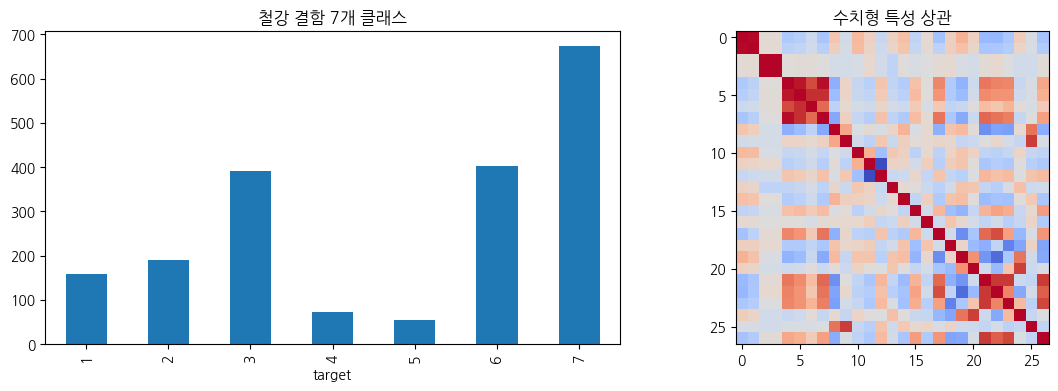

target
1    0.081401
2    0.097888
3    0.201443
4    0.037094
5    0.028336
6    0.207110
7    0.346728
Name: 비율, dtype: float64

In [2]:
set_question('1.1')
steel=load('problem1.csv');quality(steel)
assert steel['target'].nunique()==7
fig,axs=plt.subplots(1,2,figsize=(12,4))
steel.target.value_counts().sort_index().plot.bar(ax=axs[0],title='철강 결함 7개 클래스')
steel.drop(columns='target').select_dtypes('number').corr().pipe(lambda z: axs[1].imshow(z,cmap='coolwarm',vmin=-1,vmax=1))
axs[1].set_title('수치형 특성 상관');fig.tight_layout();plt.show()
display(steel.target.value_counts(normalize=True).sort_index().rename('비율'))

### 1.2

서로 중복되는 측정 특성과 결함 형상을 표현할 파생변수를 검토하시오. VIF를 참고한 변수 선택 근거와 test 20% 분할·내부 검증 설계를 제시하고 분할별 분포를 비교하시오.

**판단 및 풀이 근거**

test 20%를 먼저 보류하고 나머지 80% 안에서 validation을 25%로 분리하여 전체 60/20/20으로 구성합니다. 폭·높이·경계 사각형 면적·평균 밝기를 결정적 수식으로 생성합니다. VIF는 학습 자료에서 중앙값 대치 후 산출하고, 상수열·선형 종속을 제거한 뒤 최대 VIF가 10을 넘는 열을 순차 제거합니다. VIF 기준은 선형 다중공선성 완화용이며 예측 성능을 보장하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,removed,VIF
0,X_Minimum,inf
1,Y_Minimum,inf
2,TypeOfSteel_A300,inf
3,mean_luminosity,2.528281e+07
4,Y_Perimeter,3.230570e+03
5,LogOfAreas,1.321516e+03
6,plate_width,6.667941e+02
7,Pixels_Areas,5.206722e+02
8,plate_height,3.689137e+02
9,X_Perimeter,8.323696e+01


,최종 VIF
X_Maximum,1.245187
Y_Maximum,1.087868
Minimum_of_Luminosity,4.433592
Maximum_of_Luminosity,4.505643
Length_of_Conveyer,1.385187
TypeOfSteel_A400,1.512186
Steel_Plate_Thickness,1.252057
Edges_Index,1.288488
Empty_Index,1.981843
Square_Index,1.245073


,partition,n
0,train,1164
1,valid,388
2,test,389


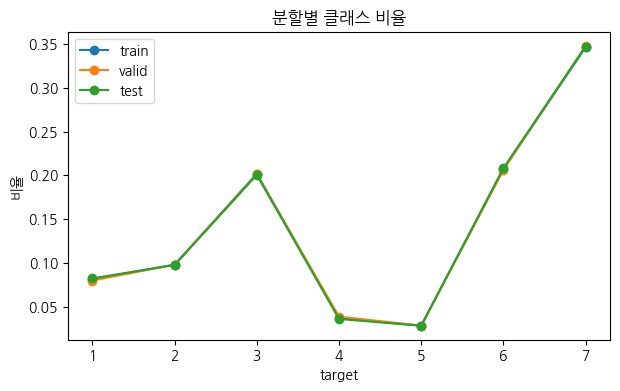

,count,mean,std,min,25%,50%,75%,max
X_Maximum,1164.0,6.237122e+02,5.002347e+02,5.0000,193.000000,4.655000e+02,1.088000e+03,1.713000e+03
Y_Maximum,1164.0,1.638211e+06,1.829186e+06,6724.0000,435211.750000,1.142048e+06,2.138789e+06,1.280652e+07
Minimum_of_Luminosity,1164.0,8.417182e+01,3.181065e+01,0.0000,62.000000,8.950000e+01,1.060000e+02,1.950000e+02
Maximum_of_Luminosity,1164.0,1.301486e+02,1.862323e+01,39.0000,124.000000,1.270000e+02,1.400000e+02,2.530000e+02
Length_of_Conveyer,1164.0,1.455902e+03,1.432115e+02,1227.0000,1358.000000,1.364000e+03,1.650000e+03,1.715000e+03
TypeOfSteel_A400,1164.0,6.168385e-01,4.863661e-01,0.0000,0.000000,1.000000e+00,1.000000e+00,1.000000e+00
Steel_Plate_Thickness,1164.0,7.895275e+01,5.387406e+01,40.0000,40.000000,7.000000e+01,8.000000e+01,3.000000e+02
Edges_Index,1164.0,3.270411e-01,2.964721e-01,0.0000,0.060400,2.263000e-01,5.654750e-01,9.923000e-01
Empty_Index,1164.0,4.142492e-01,1.361355e-01,0.0000,0.316575,4.121000e-01,5.018750e-01,9.439000e-01
Square_Index,1164.0,5.661683e-01,2.697313e-01,0.0083,0.363600,5.625000e-01,8.130750e-01,1.000000e+00


In [3]:
set_question('1.2')
X=steel.drop(columns='target').copy();y=steel.target.to_numpy()
X['plate_width']=X.X_Maximum-X.X_Minimum
X['plate_height']=X.Y_Maximum-X.Y_Minimum
X['bounding_area']=X.plate_width*X.plate_height
X['mean_luminosity']=X.Sum_of_Luminosity / X.Pixels_Areas.replace(0,np.nan)
indices=np.arange(len(X))
train_valid,test_idx=train_test_split(indices,test_size=.2,stratify=y,random_state=SEED)
train_idx,valid_idx=train_test_split(train_valid,test_size=.25,stratify=y[train_valid],random_state=SEED)
from statsmodels.stats.outliers_influence import variance_inflation_factor
Z=X.iloc[train_idx].copy();Z=Z.fillna(Z.median());Z=Z.loc[:,Z.nunique()>1]
removed=[]
with warnings.catch_warnings():
    warnings.simplefilter('ignore',RuntimeWarning)
    while len(Z.columns)>2:
        scaled=StandardScaler().fit_transform(Z);design=sm.add_constant(scaled)
        values=pd.Series([variance_inflation_factor(design,j+1) for j in range(Z.shape[1])],index=Z.columns)
        worst=values.replace(np.inf,1e100).idxmax()
        if values[worst]<=10:break
        removed.append({'removed':worst,'VIF':values[worst]});Z=Z.drop(columns=worst)
selected=Z.columns.tolist();X=X[selected]
display(pd.DataFrame(removed));display(values.rename('최종 VIF').to_frame())
display(pd.DataFrame({'partition':['train','valid','test'],'n':[len(train_idx),len(valid_idx),len(test_idx)]}))
fig,ax=plt.subplots(figsize=(7,4))
for ids,name in [(train_idx,'train'),(valid_idx,'valid'),(test_idx,'test')]:
    proportions=pd.Series(y[ids]).value_counts(normalize=True).sort_index();ax.plot(proportions.index,proportions.values,marker='o',label=name)
ax.set(title='분할별 클래스 비율',xlabel='target',ylabel='비율');ax.legend();plt.show()
display(X.iloc[train_idx].describe().T)

### 1.3

검사팀은 target=1과 그 외 결함을 먼저 구별하고자 한다. 이진 타깃을 구성하고 확률 모형과 판정 임계값을 선정하시오. 검증 자료로 임계값을 정한 근거와 혼동행렬을 제시하시오.

**판단 및 풀이 근거**

원 target=1을 양성 1, 나머지를 음성 0으로 재코딩합니다. 대치·표준화·로지스틱 회귀는 train에서 적합합니다. validation의 F1을 최대화하는 임계값을 선택하고, 동률이면 0.5에 가까운 값을 택합니다. 최종 test에서는 고정된 임계값의 혼동행렬을 한 번 평가합니다. 임계값 선택 기준은 실제 업무의 오탐·미탐 비용에 따라 바꿀 수 있습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

validation에서 정한 cutoff: 0.31


,threshold,F1,distance_to_half
31,0.31,0.645161,0.19
35,0.35,0.644068,0.15
33,0.33,0.644068,0.17
34,0.34,0.644068,0.16
36,0.36,0.644068,0.14


Accuracy            0.910026
BalancedAccuracy    0.780287
F1_macro            0.741773
F1_weighted         0.915920
ROC_AUC             0.913515
AveragePrecision    0.521217
Name: 최종 test, dtype: float64

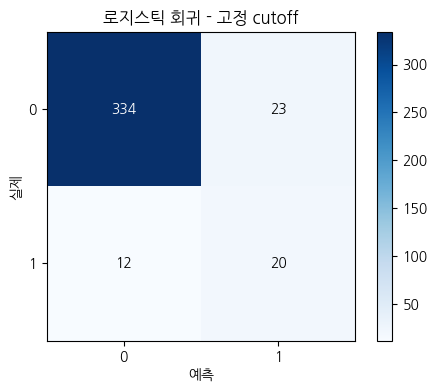

,0,1
0,334,23
1,12,20


,표준화 좌표계 계수
Square_Index,-1.210999
Outside_X_Index,-0.951955
Minimum_of_Luminosity,-0.901155
Empty_Index,-0.731209
SigmoidOfAreas,-0.389451
bounding_area,-0.130186
Edges_X_Index,-0.077772
Edges_Index,-0.076038
Luminosity_Index,0.041477
Steel_Plate_Thickness,0.050785


In [4]:
set_question('1.3')
y_binary=(y==1).astype(int)
logistic=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,random_state=SEED))])
logistic.fit(X.iloc[train_idx],y_binary[train_idx])
valid_prob=logistic.predict_proba(X.iloc[valid_idx])[:,1]
thresholds=np.linspace(0,1,101)
cut_table=pd.DataFrame({'threshold':thresholds,'F1':[f1_score(y_binary[valid_idx],valid_prob>=t,zero_division=0) for t in thresholds]})
cut_table['distance_to_half']=(cut_table.threshold-.5).abs()
cut=float(cut_table.sort_values(['F1','distance_to_half','threshold'],ascending=[False,True,True]).iloc[0].threshold)
print('validation에서 정한 cutoff:',cut);display(cut_table.sort_values('F1',ascending=False).head())
prob=logistic.predict_proba(X.iloc[test_idx])[:,1];pred=(prob>=cut).astype(int)
display(pd.Series(class_metrics(y_binary[test_idx],pred,prob),name='최종 test'))
display(plot_confusion(y_binary[test_idx],pred,labels=[0,1],title='로지스틱 회귀 - 고정 cutoff'))
coef=pd.Series(logistic.named_steps['model'].coef_[0],index=selected).sort_values()
display(coef.to_frame('표준화 좌표계 계수'))

### 1.4

이어서 7개 결함을 모두 구분하는 분류기 3개를 같은 검증 구간에서 비교하시오. 하나는 SVM으로 하고, 불균형을 고려한 선택 지표와 최종 시험 성능을 제시하시오.

**판단 및 풀이 근거**

SVM(RBF), Random Forest, 로지스틱 회귀 세 모델을 같은 train/validation에 적합·비교합니다. 7개 클래스의 불균형을 고려해 macro F1을 주 선택 지표로 사용하고 weighted F1과 accuracy를 함께 보고합니다. 선택된 모델만 최종 test에 평가합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,Accuracy,BalancedAccuracy,F1_macro,F1_weighted,fit_seconds
model,,,,,
SVM,0.760309,0.779375,0.777999,0.758407,0.117349
RandomForest,0.791237,0.788447,0.790107,0.786306,4.418085
Logistic,0.726804,0.747772,0.731843,0.722699,0.168009


validation 선택: RandomForest


Accuracy            0.796915
BalancedAccuracy    0.799646
F1_macro            0.801418
F1_weighted         0.796308
Name: 선택 모델 최종 test, dtype: float64

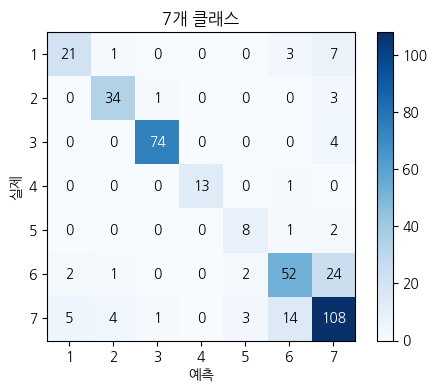

,1,2,3,4,5,6,7
1,21,1,0,0,0,3,7
2,0,34,1,0,0,0,3
3,0,0,74,0,0,0,4
4,0,0,0,13,0,1,0
5,0,0,0,0,8,1,2
6,2,1,0,0,2,52,24
7,5,4,1,0,3,14,108


In [5]:
set_question('1.4')
candidates={'SVM':SVC(C=10,kernel='rbf',gamma='scale'),
            'RandomForest':RandomForestClassifier(n_estimators=160,random_state=SEED,n_jobs=1),
            'Logistic':LogisticRegression(max_iter=2500,random_state=SEED)}
models={};rows=[]
for name,estimator in candidates.items():
    model=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',estimator)])
    t=time.perf_counter();model.fit(X.iloc[train_idx],y[train_idx]);elapsed=time.perf_counter()-t
    rows.append({'model':name,**class_metrics(y[valid_idx],model.predict(X.iloc[valid_idx])),'fit_seconds':elapsed});models[name]=model
comparison=pd.DataFrame(rows).set_index('model');display(comparison)
best_name=comparison.F1_macro.idxmax();best=models[best_name]
print('validation 선택:',best_name)
baseline_test_prediction=best.predict(X.iloc[test_idx])
display(pd.Series(class_metrics(y[test_idx],baseline_test_prediction),name='선택 모델 최종 test'))
display(plot_confusion(y[test_idx],baseline_test_prediction,title='7개 클래스'))

### 1.5

유사한 결함 형상 정보가 분류에 도움 되는지 확인하려 한다. 정답을 쓰지 않고 학습 자료에서 군집 수와 군집을 정하고, 군집 특성 추가 전후의 동일 분류기 F1을 비교해 도입 여부를 설명하시오.

**판단 및 풀이 근거**

군집은 target을 제외한 학습 특성만으로 적합합니다. k=2~10 중 학습 silhouette가 최대인 k를 선택하고, validation/test는 기존 군집 중심으로 배정합니다. 군집 번호는 순서가 없는 범주이므로 one-hot으로 추가합니다. 1.4에서 고른 같은 종류의 모델을 같은 train에 다시 적합하여 동일 test의 baseline과 macro/weighted F1을 비교합니다. test 차이는 보고용이며 추가 튜닝에 사용하지 않습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,k,silhouette,inertia
0,2,0.208707,16570.463833
1,3,0.178805,14720.919873
2,4,0.184635,13505.780842
3,5,0.184776,12343.438000
4,6,0.182819,12152.635972
5,7,0.183428,11116.058765
6,8,0.190908,10443.278304
7,9,0.190682,9960.027111
8,10,0.194038,9567.277797


,Accuracy,BalancedAccuracy,F1_macro,F1_weighted
model,,,,
baseline,0.796915,0.799646,0.801418,0.796308
cluster augmented,0.781491,0.771855,0.779660,0.780816


선택 k: 2 macro F1 변화: -0.021757546404911565


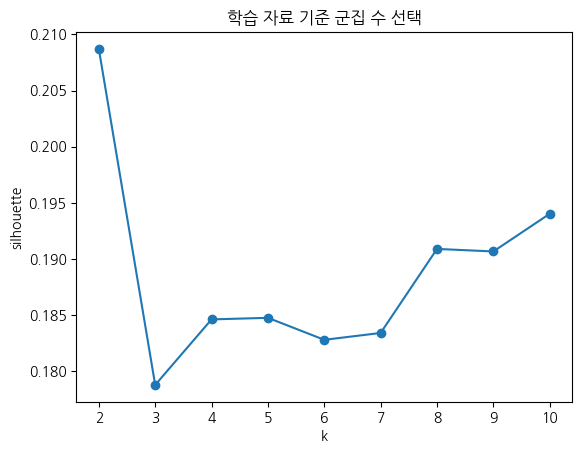

In [6]:
set_question('1.5')
cluster_preprocess=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
cluster_train=cluster_preprocess.fit_transform(X.iloc[train_idx])
cluster_curves=[];cluster_models={}
for k in range(2,11):
    km=KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(cluster_train)
    score=silhouette_score(cluster_train,km.labels_,sample_size=min(800,len(cluster_train)),random_state=SEED)
    cluster_curves.append({'k':k,'silhouette':score,'inertia':km.inertia_});cluster_models[k]=km
k_table=pd.DataFrame(cluster_curves);display(k_table)
k=int(k_table.loc[k_table.silhouette.idxmax(),'k']);km=cluster_models[k]
clusters=km.predict(cluster_preprocess.transform(X))
encoder=ohe();encoder.fit(clusters[train_idx,None]);cluster_features=encoder.transform(clusters[:,None])
base_imputer=SimpleImputer(strategy='median').fit(X.iloc[train_idx]);base_values=base_imputer.transform(X)
augmented=np.column_stack([base_values,cluster_features])
augmented_model=Pipeline([('scale',StandardScaler()),('model',clone(candidates[best_name]))])
augmented_model.fit(augmented[train_idx],y[train_idx]);aug_pred=augmented_model.predict(augmented[test_idx])
result=pd.DataFrame([{'model':'baseline',**class_metrics(y[test_idx],baseline_test_prediction)},
                     {'model':'cluster augmented',**class_metrics(y[test_idx],aug_pred)}]).set_index('model')
display(result);print('선택 k:',k,'macro F1 변화:',result.loc['cluster augmented','F1_macro']-result.loc['baseline','F1_macro'])
export=steel.copy();export['Cluster']=clusters;export.to_csv(OUT/'철강_군집레이블.csv',index=False)
fig,ax=plt.subplots();ax.plot(k_table.k,k_table.silhouette,marker='o');ax.set(xlabel='k',ylabel='silhouette',title='학습 자료 기준 군집 수 선택');plt.show()

## 2. 전력 사용 패턴

전력관리팀은 A~E 유형의 누적 계량값과 일별 기온으로 사용 패턴을 설명하려 한다. 계량값은 00·06·12·18시에 0으로 초기화된다. 날짜의 연속성 때문에 독립성 가정의 한계도 논의한다.

자료: problem2_usage.csv + problem2_usage_history.csv + problem2_avg_tem.csv

### 2-1

누적값을 그대로 더하면 총사용량이 왜곡된다. 각 6시간 구간의 마지막 값으로 일별 사용량을 복원하고, 유형별 연월 합계 CSV를 작성하시오. 원문 출력 예시의 열 구조를 참고하시오.

**판단 및 풀이 근거**

누적값을 분 단위로 모두 더하면 중복 집계됩니다. 각 6시간 블록의 마지막 시각만 취합니다. history에는 날짜가 없으므로 마지막 시각의 A~E 합(소수점 4자리)을 usage의 고유 총량과 1:1로 연결하여 epoch timestamp를 복원합니다. 일별·월별 유형 합계를 구하고 usage 전체 합과 일치하는지 검증합니다. 연월별 A~E 표와 전체 총량 CSV를 모두 저장합니다.

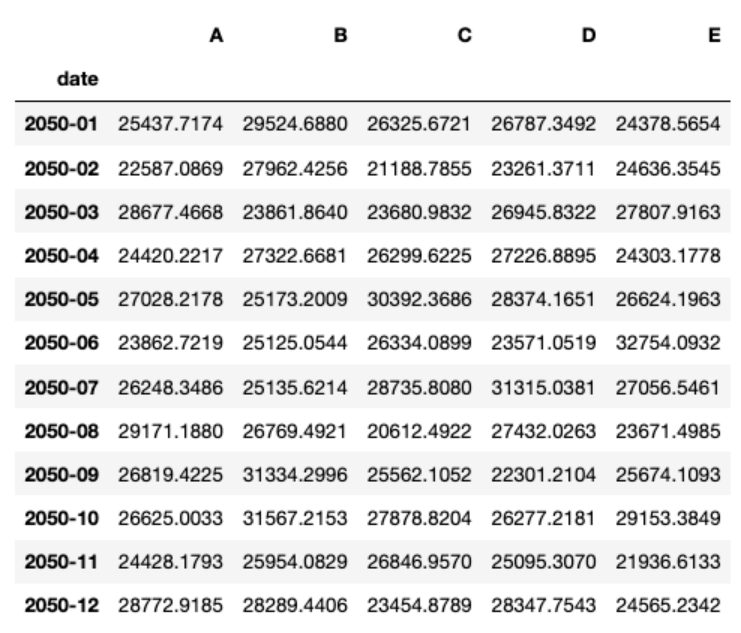

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

In [7]:
set_question('2-1')
usage=load('problem2_usage.csv');history=load('problem2_usage_history.csv');temperature=load('problem2_avg_tem.csv')
types=list('ABCDE')
usage['date_time']=pd.to_datetime(usage.timestamp,unit='s',utc=True).dt.tz_localize(None)
usage['usage']=usage.usage.round(4)
endpoints=history[history['hh:mm'].isin(['05:59','11:59','17:59','23:59'])].copy()
endpoints['usage']=endpoints[types].sum(axis=1).round(4)
assert usage.usage.is_unique and endpoints.usage.is_unique, '총량 중복이면 이 방식으로 날짜를 식별할 수 없습니다.'
blocks=endpoints.merge(usage[['usage','date_time']],on='usage',how='left',validate='one_to_one')
assert len(blocks)==len(usage) and blocks.date_time.notna().all()
assert blocks.groupby(blocks.date_time.dt.date).size().eq(4).all()
blocks['date']=blocks.date_time.dt.normalize()
daily=blocks.groupby('date')[types].sum().sort_index()
monthly=daily.groupby(daily.index.to_period('M')).sum().round(4)
monthly.index=monthly.index.astype(str);monthly.index.name='date'
monthly_total=usage.groupby(usage.date_time.dt.to_period('M')).usage.sum().round(4)
np.testing.assert_allclose(monthly.sum(axis=1).to_numpy(),monthly_total.to_numpy(),atol=1e-4)
assert len(daily)==365 and len(monthly)==12
display(monthly)
monthly.to_csv(OUT/'전력_연월별_유형별합계.csv');monthly_total.to_csv(OUT/'전력_연월별_전체총합.csv',header=['usage'])
daily.to_csv(OUT/'전력_일자별_유형별합계.csv')
print('누적 초기화 직전 블록:',len(blocks),'일자:',len(daily),'연간 총량:',round(monthly_total.sum(),4))

,A,B,C,D,E
date,,,,,
2050-01,25437.7174,29524.6880,26325.6721,26787.3492,24378.5654
2050-02,22587.0869,27962.4256,21188.7855,23261.3711,24636.3545
2050-03,28677.4668,23861.8640,23680.9832,26945.8322,27807.9163
2050-04,24420.2217,27322.6681,26299.6225,27226.8895,24303.1778
2050-05,27028.2178,25173.2009,30392.3686,28374.1651,26624.1963
2050-06,23862.7219,25125.0544,26334.0899,23571.0519,32754.0932
2050-07,26248.3486,25135.6214,28735.8080,31315.0381,27056.5461
2050-08,29171.1880,26769.4921,20612.4922,27432.0263,23671.4985
2050-09,26819.4225,31334.2996,25562.1052,22301.2104,25674.1093


누적 초기화 직전 블록: 1460 일자: 365 연간 총량: 1578908.0321


### 2-2

운영 담당자가 요일별 차이를 파악할 수 있도록 일~토 순서의 유형별 평균 일일 사용량을 하나의 그래프에 표시하고 차이를 설명하시오.

**판단 및 풀이 근거**

원문의 “일~월”은 7개 요일의 순서를 명확히 지정하지 않습니다. 일요일부터 토요일까지 주 7일을 모두 표시합니다. 일별 총량을 만든 후 요일별 평균을 구하므로 특정 요일의 관측 일수가 달라도 비교 기준이 같습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 결과와 위 판단 근거를 연결해 답안을 작성합니다.

,A,B,C,D,E
일,1027.717515,1257.153342,1239.575981,1250.460054,1252.367971
월,673.744471,775.036663,702.495327,778.445513,694.785656
화,793.740256,775.320904,717.699188,723.901138,720.253840
수,758.510413,703.582162,701.678988,708.008392,699.895421
목,762.993615,693.684079,643.619888,709.325115,788.118737
금,778.184223,765.871610,689.122890,731.251890,688.666733
토,1221.588434,1312.194668,1192.728034,1170.996675,1144.699909


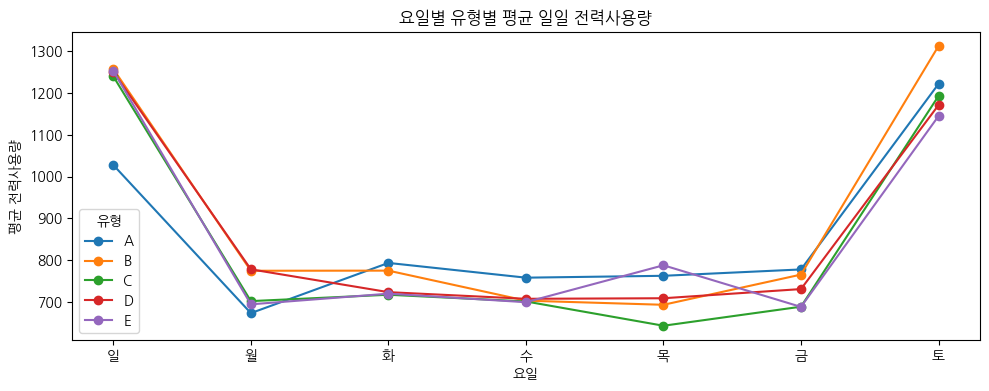

In [8]:
set_question('2-2')
weekday=daily.groupby(daily.index.dayofweek).mean().reindex([6,0,1,2,3,4,5])
weekday.index=['일','월','화','수','목','금','토'];display(weekday)
fig,ax=plt.subplots(figsize=(10,4))
for t in types:ax.plot(weekday.index,weekday[t],marker='o',label=t)
ax.set(title='요일별 유형별 평균 일일 전력사용량',xlabel='요일',ylabel='평균 전력사용량');ax.legend(title='유형');fig.tight_layout();plt.show()

### 2-3

유형별 평균 일일 사용량이 요일에 따라 다른지 평가하려 한다. 일별 관측을 사용한 검정 방법과 가정·가설을 제시하고, 5개 유형의 p-value를 다중검정 보정한 뒤 결론을 작성하시오. 시계열 의존성에 따른 한계를 설명하시오.

**판단 및 풀이 근거**

독립 일별 표본을 작업 가정으로 한 Welch 일원 평균 비교를 유형별로 수행하고 Holm 보정한다. 실제 연속 일별 자료의 자기상관은 별도 점검이 필요하므로 이 p값을 확증 근거로 단정하지 않는다.

**계산·해석 상세**

“연관성”의 검정 대상이 모호하여 두 해석을 구분합니다. (A) 유형별 일일 사용량이 요일에 따라 다른지 Welch 일원 ANOVA로 검정하고 5개 p값을 Holm 보정합니다. (B) 문제에서 지칭한 7개 요일 평균 프로파일 간 Pearson 상관을 구하고 10개 쌍을 Holm 보정합니다. B의 표본은 평균값 7개뿐이며 요일은 고정 범주이므로 프로파일의 탐색적 연관성으로 해석합니다. 일별 시계열의 독립성과 정규 근사는 별도로 확인해야 합니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

In [9]:
set_question('2-3')
rows=[]
for t in types:
    groups=[daily.loc[daily.index.dayofweek==d,t].to_numpy() for d in range(7)]
    test=anova_oneway(groups,use_var='unequal')
    rows.append({'type':t,'Welch_F':test.statistic,'p_value':test.pvalue})
weekday_tests=pd.DataFrame(rows);weekday_tests['p_Holm']=multipletests(weekday_tests.p_value,method='holm')[1]
weekday_tests['결론']=weekday_tests.p_Holm.map(decision);display(weekday_tests)
from itertools import combinations
rows=[]
for a,c in combinations(types,2):
    r,pvalue=stats.pearsonr(weekday[a],weekday[c]);rows.append({'type1':a,'type2':c,'r':r,'p_value':pvalue,'n':7})
profile_tests=pd.DataFrame(rows);profile_tests['p_Holm']=multipletests(profile_tests.p_value,method='holm')[1]
display(profile_tests)
print('H0(A): 각 유형에서 모든 요일의 평균 사용량이 같다. H0(B): 두 유형의 요일 평균 프로파일 상관이 0이다.')

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
for i,t in enumerate(types):
    row=weekday_tests.iloc[i]
    report_test('Welch 일원 평균 비교: '+t,'모든 요일의 평균 일일 사용량이 같다','적어도 한 요일의 평균이 다르다',row.Welch_F,row.p_value,t+' 유형 사용량에 요일 차이가 있다','요일 간 독립을 작업 가정으로 계산. 시계열 의존성을 무시한 p값은 탐색적이다.',adjusted_p=row.p_Holm)

,type,Welch_F,p_value,p_Holm,결론
0,A,12.025997,4.126986e-11,4.126986e-11,귀무가설 기각
1,B,18.361958,3.870255e-16,1.935127e-15,귀무가설 기각
2,C,15.068786,1.310641e-13,5.242565e-13,귀무가설 기각
3,D,15.064360,1.317643e-13,5.242565e-13,귀무가설 기각
4,E,13.811790,1.354735e-12,2.709469e-12,귀무가설 기각


,type1,type2,r,p_value,n,p_Holm
0,A,B,0.940658,0.001596,7,0.006382
1,A,C,0.915500,0.003808,7,0.011423
2,A,D,0.883684,0.008316,7,0.015071
3,A,E,0.888298,0.007535,7,0.015071
4,B,C,0.989523,0.000021,7,0.000193
5,B,D,0.983800,0.000064,7,0.000509
6,B,E,0.953863,0.000857,7,0.004283
7,C,D,0.993184,0.000007,7,0.000073
8,C,E,0.973209,0.000222,7,0.001334
9,D,E,0.978214,0.000133,7,0.000931


H0(A): 각 유형에서 모든 요일의 평균 사용량이 같다. H0(B): 두 유형의 요일 평균 프로파일 상관이 0이다.
{
  "question": "2-3",
  "method": "Welch 일원 평균 비교: A",
  "H0": "모든 요일의 평균 일일 사용량이 같다",
  "H1": "적어도 한 요일의 평균이 다르다",
  "statistic": 12.025996951856673,
  "p_value": 4.1269861028409e-11,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "요일 간 독립을 작업 가정으로 계산. 시계열 의존성을 무시한 p값은 탐색적이다.",
  "conclusion": "귀무가설을 기각한다. A 유형 사용량에 요일 차이가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 4.1269861028409e-11,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "2-3",
  "method": "Welch 일원 평균 비교: B",
  "H0": "모든 요일의 평균 일일 사용량이 같다",
  "H1": "적어도 한 요일의 평균이 다르다",
  "statistic": 18.36195842443114,
  "p_value": 3.8702548570520105e-16,
  "alpha": 0.05,
  "reject_H0": true,
  "assumptions": "요일 간 독립을 작업 가정으로 계산. 시계열 의존성을 무시한 p값은 탐색적이다.",
  "conclusion": "귀무가설을 기각한다. B 유형 사용량에 요일 차이가 있다는 통계적 근거가 있다.",
  "adjusted_p_value": 1.935127428526005e-15,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "2-3",
  "method": "Welch 일원 평균 비교: C",
  "H0": "모든 

### 2-4

기온이 높은 날에 유형별 사용량이 증가하거나 감소하는지 평가하려 한다. 날짜를 맞춰 두 자료를 결합하고 관계의 방향·크기와 검정 p-value·가설·기각 여부를 제시하시오. 여러 관계를 동시에 살핀다는 점과 인과 해석의 한계를 설명하시오.

**판단 및 풀이 근거**

기온·사용량은 수치형이고 선형 관계를 탐색하므로 Pearson을 주 분석으로, 순위 관계는 보조로 본다. H0: rho=0, H1: rho≠0이며 5개 비교는 Holm 보정한다.

**계산·해석 상세**

일별 A~E 사용량과 일별 평균 온도를 날짜로 1:1 연결한 후 Pearson 상관을 계산합니다. 5개 상관 검정은 Holm 보정하고 Spearman 상관을 보조로 제시합니다. 상관은 인과를 뜻하지 않으며, 같은 계절 추세가 두 값에 영향을 줄 수 있습니다.

**실행 답안**

아래 코드는 이 문항의 산출물과 수치를 계산합니다. 가설·통계량·p-value·기각 여부·상황 결론을 함께 출력하며 수치는 실행 결과에 따라 결정합니다.

,date,A,B,C,D,E,temperature
0,2050-01-01,1583.1230,1748.4258,719.0734,1512.2236,304.6623,6.164408
1,2050-01-02,1084.4828,2167.1320,1227.6223,484.2982,1095.9014,1.015510
2,2050-01-03,152.3612,394.0491,321.2149,982.0407,498.5167,3.691252
3,2050-01-04,1225.0208,769.0568,655.4110,791.3395,834.6589,4.071515
4,2050-01-05,836.8017,552.5661,1216.6259,1042.4509,666.6004,0.609249


,type,Pearson_r,p_value,Spearman_rho,n,p_Holm
0,A,0.001472,0.977648,0.008590,365,1.000000
1,B,-0.048002,0.360474,-0.027513,365,1.000000
2,C,0.045952,0.381372,0.041754,365,1.000000
3,D,-0.010146,0.846818,-0.031344,365,1.000000
4,E,0.074246,0.156908,0.062194,365,0.784539


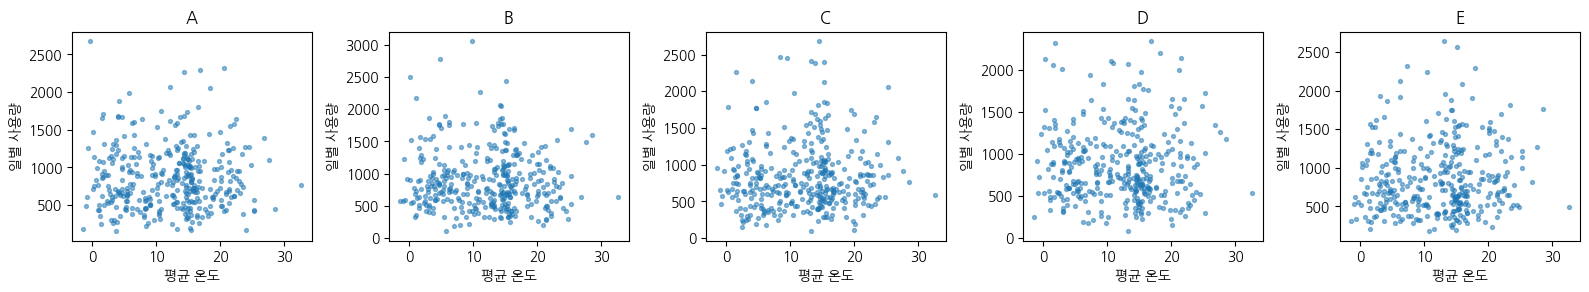

{
  "question": "2-4",
  "method": "Pearson 기온-사용량: A",
  "H0": "모상관 rho=0",
  "H1": "모상관 rho != 0",
  "statistic": 0.0014715353493160814,
  "p_value": 0.9776484115081793,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립·이변량 정규 추론을 작업 가정. 날짜 의존성·다중 비교·인과 해석에 주의.",
  "conclusion": "귀무가설을 기각하지 못한다. A 사용량과 기온에 선형 관계가 있다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "adjusted_p_value": 1.0,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "2-4",
  "method": "Pearson 기온-사용량: B",
  "H0": "모상관 rho=0",
  "H1": "모상관 rho != 0",
  "statistic": -0.04800219563981737,
  "p_value": 0.3604739971140835,
  "alpha": 0.05,
  "reject_H0": false,
  "assumptions": "독립·이변량 정규 추론을 작업 가정. 날짜 의존성·다중 비교·인과 해석에 주의.",
  "conclusion": "귀무가설을 기각하지 못한다. B 사용량과 기온에 선형 관계가 있다는 통계적 근거가 충분하지 않다. 귀무가설의 참을 입증한 것은 아니다.",
  "adjusted_p_value": 1.0,
  "decision_basis": "Holm 보정 p값"
}
{
  "question": "2-4",
  "method": "Pearson 기온-사용량: C",
  "H0": "모상관 rho=0",
  "H1": "모상관 rho != 0",
  "statistic": 0.04595245682182118

In [10]:
set_question('2-4')
temperature['date']=pd.to_datetime(temperature.date)
joined=daily.reset_index().merge(temperature,on='date',validate='one_to_one')
assert len(joined)==365 and joined[['temperature']+types].notna().all().all()
display(joined.head());rows=[]
for t in types:
    r,pvalue=stats.pearsonr(joined.temperature,joined[t]);rho,sp=stats.spearmanr(joined.temperature,joined[t])
    rows.append({'type':t,'Pearson_r':r,'p_value':pvalue,'Spearman_rho':rho,'n':len(joined)})
correlations=pd.DataFrame(rows);correlations['p_Holm']=multipletests(correlations.p_value,method='holm')[1]
display(correlations);joined.to_csv(OUT/'전력_일별_온도결합.csv',index=False)
fig,axs=plt.subplots(1,5,figsize=(16,3))
for ax,t in zip(axs,types):ax.scatter(joined.temperature,joined[t],s=8,alpha=.5);ax.set(title=t,xlabel='평균 온도',ylabel='일별 사용량')
fig.tight_layout();plt.show()

# 상황형 요구: 가설·실제 수치·기각 여부·맥락 결론
for _,row in correlations.iterrows():
    report_test('Pearson 기온-사용량: '+row['type'],'모상관 rho=0','모상관 rho != 0',row.Pearson_r,row.p_value,row['type']+' 사용량과 기온에 선형 관계가 있다','독립·이변량 정규 추론을 작업 가정. 날짜 의존성·다중 비교·인과 해석에 주의.',adjusted_p=row.p_Holm)

## 제출 전 확인

- 문항별 요구 산출물과 수치를 위 결과에서 확인합니다.
- 데이터 변형·모형·지표·가설의 조건을 답안과 함께 제출합니다.
- p ≥ 0.05는 귀무가설이 참임을 입증하는 것이 아니라 기각 근거 부족입니다.
- 모델 선택은 validation 결과로 했으며 최종 test 지표로 재튜닝하지 않습니다.
- 원문 표현의 모호성·자료의 오류는 풀이에서 명시하고 임의로 원문을 수정하지 않았습니다.